# ⚡ Smart Energy Forecasting with an AI Planning Assistant

**Project 6** - forecast tomorrow's hourly German electricity price and solar generation
(with a low / middle / high range), compare baselines vs **LSTM** vs **1D-CNN** vs **PatchTST**,
and let a planning assistant pick the cheapest hours to charge an electric car or run a heat pump.

| Step | What | Output |
|---|---|---|
| 1 | Download hourly market data from SMARD | `data/raw/*.csv` |
| 2 | Clean, merge, add calendar features | `data/processed/dataset_hourly.csv` |
| 3 | Split by time, scale, 7-day → 24-hour windows | train / val / test |
| 4 | Train and compare models | results table, best model |
| 5 | Planning assistant (optimizer + LLM) | charging / heating plan |
| 6 | Streamlit app | `streamlit run app.py` |

Data: Bundesnetzagentur | SMARD.de (CC BY 4.0).  The heavy lifting lives in `src/` so the notebook and the app share the same code.

## 0. Setup

In [1]:
# On Google Colab: upload/clone the project folder first, then uncomment:
# !pip install -q holidays neuralforecast
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import config
from src.config import FEATURES, TARGETS, MODELS_DIR
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (12, 4)
print("project root:", ROOT, "| torch", torch.__version__)

project root: . | torch 2.15.0


In [2]:
# Switches: set to False to reuse what is already on disk
DOWNLOAD = True        # fetch the newest SMARD data (~30 s)
TRAIN = True           # train LSTM + 1D-CNN (minutes on a GPU / Apple MPS)
RUN_PATCHTST = True    # PatchTST: ~1.5 min on the Apple GPU (MPS); set False to reuse models/patchtst/
EPOCHS = config.MAX_EPOCHS

## 1. Download the data (SMARD)

Region **Germany/Luxembourg**, resolution **hour**, 01.01.2019 – today.
`src/download_data.py` uses SMARD's public chart-data API (same data as the download center, no account).

| Priority | Series |
|---|---|
| Must-have | wholesale price, actual solar / wind onshore / wind offshore, grid load, residual load |
| Recommended | day-ahead forecasts of solar, wind and load |

In [3]:
from src.download_data import download_all
from src.config import SMARD_SERIES

if DOWNLOAD:
    download_all()
pd.DataFrame(SMARD_SERIES, index=["filter_id", "region", "description"]).T

price                69120 rows  last=2026-11-19 23:00  -> price.csv


solar                69085 rows  last=2026-11-18 12:00  -> solar.csv


wind_onshore         69085 rows  last=2026-11-18 12:00  -> wind_onshore.csv


wind_offshore        69085 rows  last=2026-11-18 12:00  -> wind_offshore.csv


load                 69081 rows  last=2026-11-18 08:00  -> load.csv


residual_load        69081 rows  last=2026-11-18 08:00  -> residual_load.csv


solar_fc             69096 rows  last=2026-11-18 23:00  -> solar_fc.csv


wind_onshore_fc      69096 rows  last=2026-11-18 23:00  -> wind_onshore_fc.csv


wind_offshore_fc     69096 rows  last=2026-11-18 23:00  -> wind_offshore_fc.csv


load_fc              69096 rows  last=2026-11-19 23:00  -> load_fc.csv


,filter_id,region,description
price,4169,DE-LU,Market > Wholesale price DE/LU (EUR/MWh)
solar,4068,DE,Actual generation > Photovoltaics (MWh)
wind_onshore,4067,DE,Actual generation > Wind onshore (MWh)
wind_offshore,1225,DE,Actual generation > Wind offshore (MWh)
load,410,DE,Actual consumption > Total grid load (MWh)
residual_load,4359,DE,Actual consumption > Residual load (MWh)
solar_fc,125,DE,Forecasted generation day-ahead > Photovoltaic...
wind_onshore_fc,123,DE,Forecasted generation day-ahead > Wind onshore...
wind_offshore_fc,3791,DE,Forecasted generation day-ahead > Wind offshor...
load_fc,411,DE,Forecasted consumption > Total grid load (MWh)


## 2. Build the dataset → `dataset_hourly.csv`

* timestamps in German local time; October duplicate hour dropped, March missing hour filled
* quarter-hourly values averaged to hourly · price €/MWh ÷ 10 → **ct/kWh**
* gaps ≤ 3 h interpolated, incomplete rows dropped
* calendar features: hour, weekday, weekend, German holiday, sine/cosine of hour and day of year

In [4]:
from src.build_dataset import build_dataset, load_dataset

build_dataset()
df = load_dataset()
df.head()

dataset: 69081 rows (39 incomplete dropped), 2019-01-01 00:00:00 -> 2026-11-18 08:00:00  saved to ./data/processed/dataset_hourly.csv


,price,solar,wind_onshore,wind_offshore,load,residual_load,solar_fc,wind_onshore_fc,wind_offshore_fc,load_fc,hour,weekday,is_weekend,is_holiday,hour_sin,hour_cos,doy_sin,doy_cos
timestamp,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00,2.832,0.0,20314.25,3134.00,43273.75,19825.50,0.0,18879.75,5069.00,43213.25,0,1,0,1,0.0000,1.0000,0.0,1.0
2019-01-01 01:00:00,1.007,0.0,22297.25,2868.25,41631.25,16465.75,0.0,20626.50,5042.25,41275.75,1,1,0,1,0.2588,0.9659,0.0,1.0
2019-01-01 02:00:00,-0.408,0.0,23168.50,2460.25,40085.00,14456.25,0.0,22355.50,5028.50,40187.50,2,1,0,1,0.5000,0.8660,0.0,1.0
2019-01-01 03:00:00,-0.991,0.0,24471.75,2696.50,39269.75,12101.50,0.0,24032.50,4977.75,39909.00,3,1,0,1,0.7071,0.7071,0.0,1.0
2019-01-01 04:00:00,-0.741,0.0,26320.50,2578.00,39032.75,10134.25,0.0,25452.00,4907.25,40258.00,4,1,0,1,0.8660,0.5000,0.0,1.0


In [5]:
df[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
price,69081.0,9.77,9.24,-50.00,3.90,7.99,12.23,93.63
solar,69081.0,6723.73,10547.44,0.00,3.25,229.00,10486.74,57671.50
wind_onshore,69081.0,11968.11,9461.60,46.50,4524.75,9270.00,17189.50,48499.50
wind_offshore,69081.0,2902.30,1975.64,0.00,1107.00,2681.25,4587.25,9021.73
load,69081.0,54557.77,9613.66,30902.75,46739.00,54413.00,61894.50,81319.50
residual_load,69081.0,32963.62,14153.05,-15561.59,23786.25,33847.50,42751.25,74638.75
is_weekend,69081.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
is_holiday,69081.0,0.02,0.15,0.00,0.00,0.00,0.00,1.00
hour_sin,69081.0,0.00,0.71,-1.00,-0.71,0.00,0.71,1.00
hour_cos,69081.0,0.00,0.71,-1.00,-0.71,0.00,0.71,1.00


### Exploration

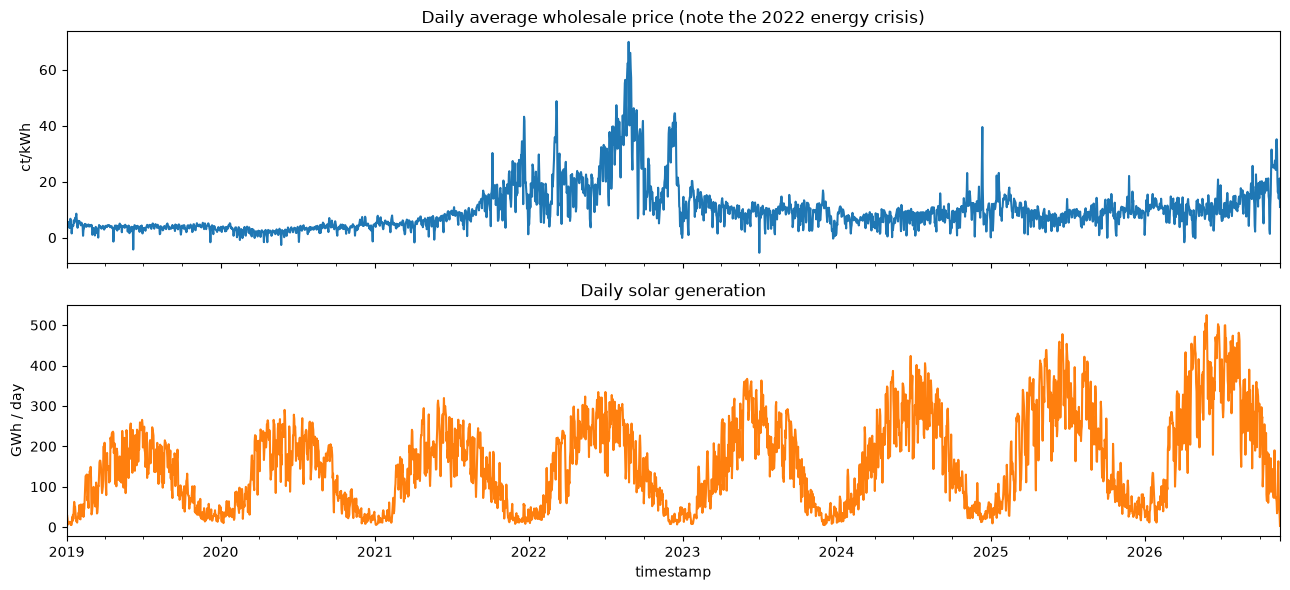

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
df["price"].resample("D").mean().plot(ax=ax[0], color="tab:blue")
ax[0].set_ylabel("ct/kWh"); ax[0].set_title("Daily average wholesale price (note the 2022 energy crisis)")
(df["solar"].resample("D").sum() / 1000).plot(ax=ax[1], color="tab:orange")
ax[1].set_ylabel("GWh / day"); ax[1].set_title("Daily solar generation")
plt.tight_layout()

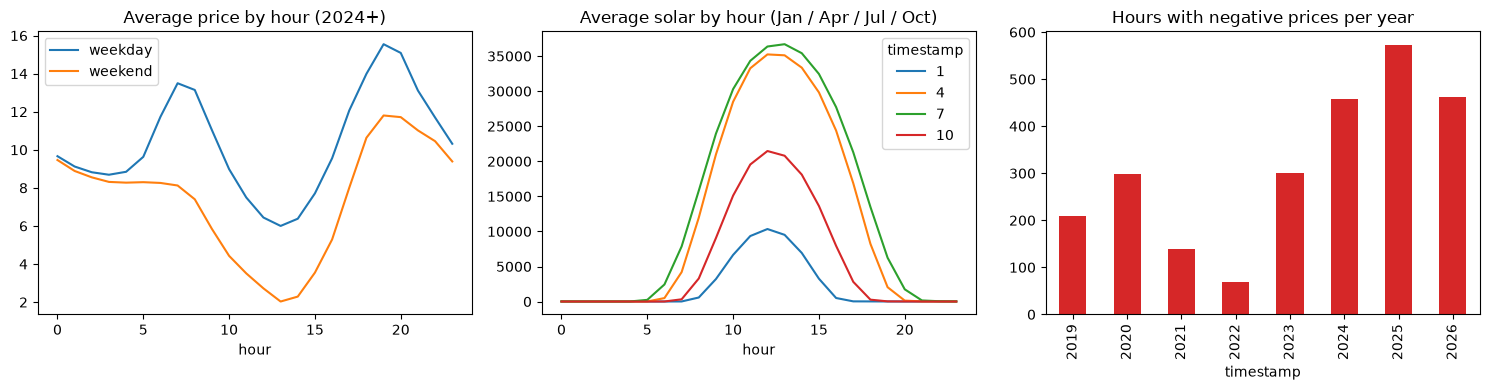

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
recent = df.loc["2024":]
recent.groupby([recent.index.hour, recent.is_weekend])["price"].mean().unstack().plot(ax=ax[0])
ax[0].set_title("Average price by hour (2024+)"); ax[0].set_xlabel("hour"); ax[0].legend(["weekday", "weekend"])
recent.groupby([recent.index.month, recent.index.hour])["solar"].mean().unstack(0)[[1, 4, 7, 10]].plot(ax=ax[1])
ax[1].set_title("Average solar by hour (Jan / Apr / Jul / Oct)"); ax[1].set_xlabel("hour")
(df["price"] < 0).groupby(df.index.year).sum().plot.bar(ax=ax[2], color="tab:red")
ax[2].set_title("Hours with negative prices per year")
plt.tight_layout()

In [8]:
df[["price", "solar", "wind_onshore", "wind_offshore", "load", "residual_load"]].corr().round(2)

,price,solar,wind_onshore,wind_offshore,load,residual_load
price,1.00,-0.17,-0.26,-0.16,0.14,0.41
solar,-0.17,1.00,-0.22,-0.22,0.18,-0.45
wind_onshore,-0.26,-0.22,1.00,0.62,0.14,-0.50
wind_offshore,-0.16,-0.22,0.62,1.00,0.16,-0.29
load,0.14,0.18,0.14,0.16,1.00,0.43
residual_load,0.41,-0.45,-0.50,-0.29,0.43,1.00


## 3. Prepare for training

* **Split by time, never randomly:** train 2019–2024 · validation 2025 · test 2026
* **StandardScaler** fitted on the training rows only
* **Sliding windows:** input = last 168 h × 12 columns, output = next 24 h of price and solar.
  Training uses every hour as a start; validation/test only midnight starts ("forecast tomorrow").

In [9]:
from src.data_prep import WindowDataset, prepare, unscale_targets

full, values, scaler, windows = prepare(df, fit=True)
for name, w in windows.items():
    print(f"{name:5s}: {len(w.starts):6d} windows   first target day {w.days()[0]:%Y-%m-%d}   last {w.days()[-1]:%Y-%m-%d}")

train_ds = WindowDataset(values, windows["train"].starts)
val_ds = WindowDataset(values, windows["val"].starts)
test_ds = WindowDataset(values, windows["test"].starts)
x, y = train_ds[0]
print("one example: input", tuple(x.shape), "-> target", tuple(y.shape))

train:  52417 windows   first target day 2019-01-08   last 2024-12-31
val  :    365 windows   first target day 2025-01-01   last 2025-12-31
test :    321 windows   first target day 2026-01-01   last 2026-11-17
one example: input (168, 12) -> target (24, 2)


## 4. Models

### 4.1 Baselines
"same hour yesterday" and "same hour last week". The low/high band comes from the baseline's
error quantiles on the training years. **Every real model must beat these.**

In [10]:
from src.evaluate import (baseline_forecast, clip_solar, fit_baseline_band, metrics,
                          raw_target_array, results_table, true_values)

raw = raw_target_array(full)
y_val = true_values(raw, windows["val"].starts)
val_preds = {}
for lag, label in ((24, "Baseline: same hour yesterday"), (168, "Baseline: same hour last week")):
    val_preds[label] = baseline_forecast(raw, windows["val"].starts, lag,
                                         fit_baseline_band(raw, windows["train"].starts, lag))
results_table({k: metrics(y_val, q) for k, q in val_preds.items()})

MAE      RMSE   Pinball  Coverage  BandWidth
target model                                                                           
price  Baseline: same hour last week     3.281     4.937     1.149      78.6     10.601
       Baseline: same hour yesterday     2.598     4.046     0.925      79.8      8.185
solar  Baseline: same hour last week  2997.850  6027.394  1031.961      58.2   6919.752
       Baseline: same hour yesterday  1763.819  3767.939   615.075      60.9   4619.796

### 4.2 LSTM and 1D-CNN with quantile (pinball) loss

Each model outputs **24 h × 2 targets × 3 quantiles = 72 numbers** (10 %, 50 %, 90 %).

| Model | Setup |
|---|---|
| LSTM | 2 layers, 128 units → dense layer → 72 outputs |
| 1D-CNN | 6 causal dilated conv layers (1, 2, 4 … 32), 64 filters, receptive field ≈ 1 week |

Adam (lr 0.001), batch 64, up to 50 epochs, early stopping after 5 epochs without validation improvement.

In [11]:
from src.train import get_device, load_model, predict, save_model, train_model

print("device:", get_device())
histories = {}
for name in ("cnn", "lstm"):
    if TRAIN or not (MODELS_DIR / f"{name}.pt").exists():
        model, hist = train_model(name, train_ds, val_ds, epochs=EPOCHS)
        save_model(model, name, hist)
    histories[name] = pd.read_json(MODELS_DIR / f"{name}_history.json")

device: mps


[cnn] epoch  1  train 0.0740  val 0.0725  (6s)


[cnn] epoch  2  train 0.0568  val 0.0724  (6s)


[cnn] epoch  3  train 0.0522  val 0.0664  (6s)


[cnn] epoch  4  train 0.0495  val 0.0666  (6s)


[cnn] epoch  5  train 0.0479  val 0.0647  (6s)


... (12 outputs left out)

[lstm] epoch  6  train 0.0419  val 0.0745  (12s)


[lstm] epoch  7  train 0.0390  val 0.0749  (12s)


[lstm] epoch  8  train 0.0364  val 0.0801  (12s)


[lstm] epoch  9  train 0.0336  val 0.0827  (12s)
[lstm] early stopping - best val pinball 0.0669


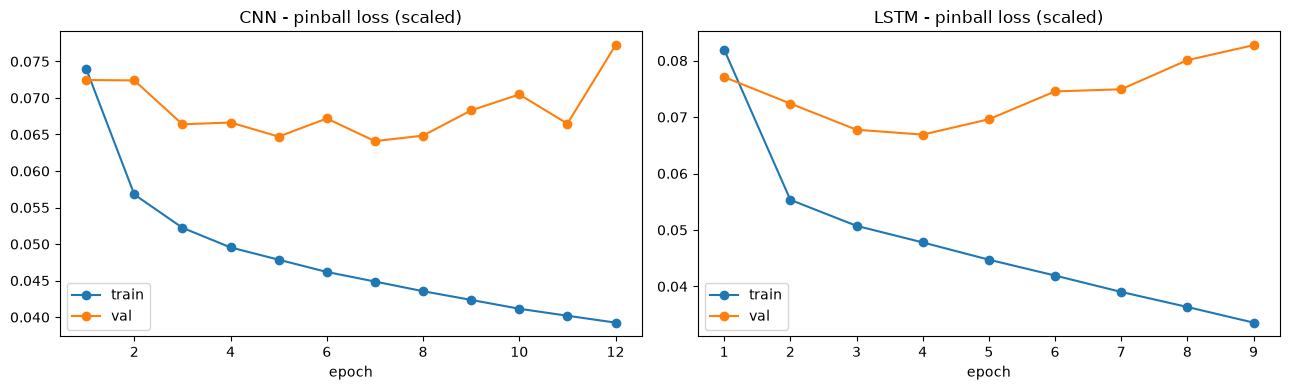

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (name, h) in zip(ax, histories.items()):
    h.plot(x="epoch", y=["train", "val"], ax=a, marker="o", title=f"{name.upper()} - pinball loss (scaled)")
plt.tight_layout()

### 4.3 PatchTST (neuralforecast)

Cuts the history into 24-hour patches; attention learns which past days matter.

* **Training data:** only the hourly history of `price` (ct/kWh) and `solar` (MWh) - one shared univariate model  
* **Train 2019–2024**, **2025 for early stopping**, then rolling day-ahead forecasts on **2026** (never trained on)  
* **Hardware:** Apple GPU (MPS) on a Mac (CUDA on Colab, CPU otherwise) - about 1.5 minutes  
* Saved to `models/patchtst/` (+ `training_info.json`) so the Streamlit app can forecast **live** with it, incl. Real mode;
  test forecasts also go to `models/patchtst_forecasts.csv` for the comparison table.

In [13]:
from src.patchtst import run_patchtst

if RUN_PATCHTST:
    run_patchtst(df, max_steps=2000)
from src.patchtst import training_info
training_info()

PatchTST forecasts available: True


## 4.4 Evaluation

**Choose on validation, confirm once on test.**
MAE / RMSE (middle forecast) · Pinball (whole range) · Coverage (goal ≈ 80 %) · Band width.

In [14]:
from src.compare import best_model, compare

val_table = compare("val")
val_table

MAE      RMSE   Pinball  Coverage  BandWidth
target model                                                                           
price  1D-CNN                            1.970     2.983     0.653      74.6      5.294
       Baseline: same hour last week     3.281     4.937     1.149      78.6     10.601
       Baseline: same hour yesterday     2.598     4.046     0.925      79.8      8.185
       LSTM                              2.037     3.065     0.673      78.1      6.061
solar  1D-CNN                         1725.530  3308.630   559.950      73.7   4338.932
       Baseline: same hour last week  2997.850  6027.394  1031.961      58.2   6919.752
       Baseline: same hour yesterday  1763.819  3767.939   615.075      60.9   4619.796
       LSTM                           1830.237  3546.354   587.844      74.7   4545.286

In [15]:
best = best_model("val")
print("Best model on validation (lowest pinball):", best)

Best model on validation (lowest pinball): 1D-CNN


In [16]:
test_table = compare("test")   # the final exam - look at it once
test_table

MAE      RMSE   Pinball  Coverage  BandWidth
target model                                                                           
price  1D-CNN                            2.656     4.021     0.872      73.3      6.875
       Baseline: same hour last week     4.461     6.789     1.599      71.0     10.601
       Baseline: same hour yesterday     3.327     5.158     1.192      72.8      8.185
       LSTM                              3.091     4.452     1.015      67.8      7.888
       PatchTST                          2.588     4.007     0.844      80.4      7.926
solar  1D-CNN                         2461.366  4517.461   855.570      64.6   4614.657
       Baseline: same hour last week  3462.118  6642.399  1191.749      53.5   6919.752
       Baseline: same hour yesterday  2254.180  4643.844   803.885      57.6   4619.796
       LSTM                           2482.189  4525.188   859.551      63.1   4907.536
       PatchTST                       2222.782  4214.482   722.825      81.5   6826.296

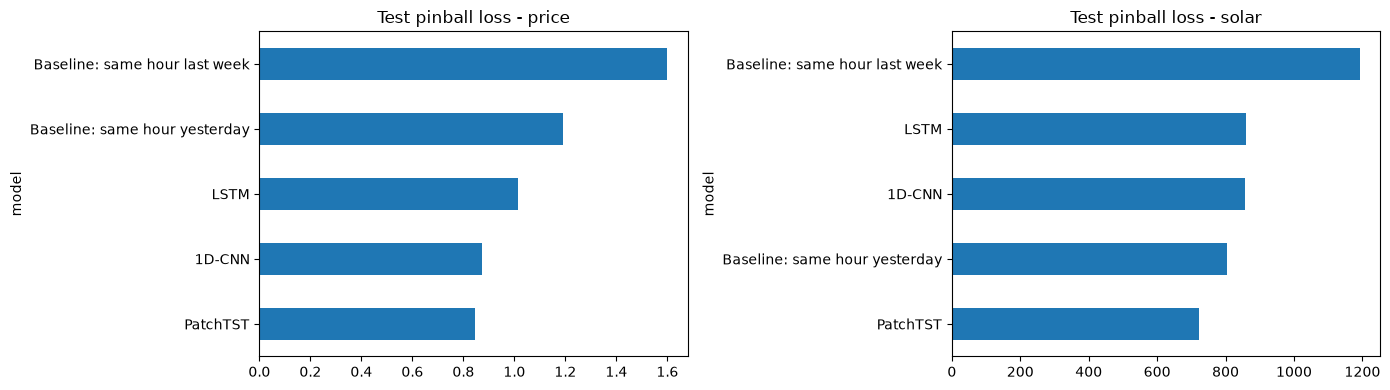

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, target in zip(ax, TARGETS):
    test_table.loc[target]["Pinball"].sort_values().plot.barh(ax=a, color="tab:blue")
    a.set_title(f"Test pinball loss - {target}")
plt.tight_layout()

### Example: forecast vs reality for one test day

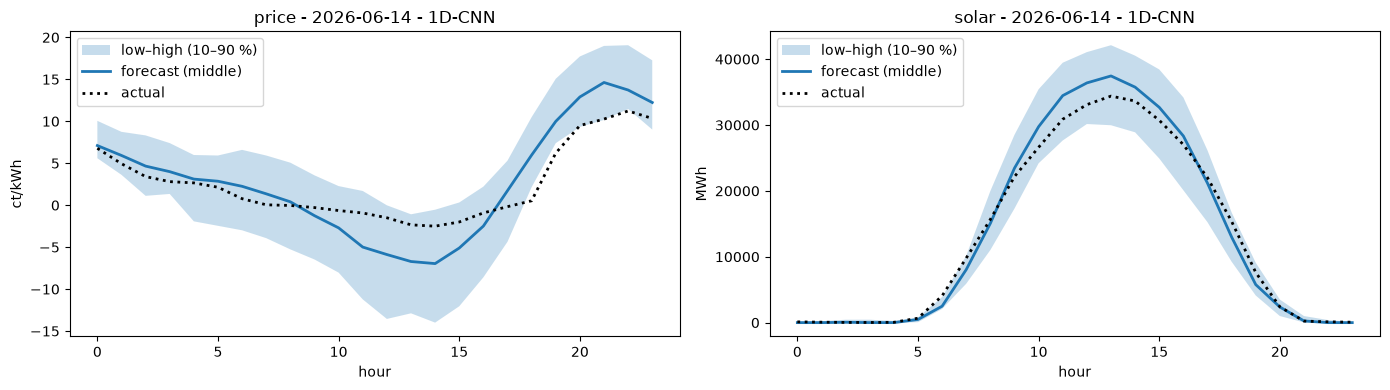

In [18]:
from src.forecast import MODEL_LABELS, ForecastService

svc = ForecastService()
DAY = "2026-06-14"   # try any day in 2026
model_key = {v: k for k, v in MODEL_LABELS.items()}.get(best, "cnn")
fc = svc.forecast_day(DAY, model_key)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (t, unit) in zip(ax, (("price", "ct/kWh"), ("solar", "MWh"))):
    h = fc.timestamp.dt.hour
    a.fill_between(h, fc[f"{t}_lo"], fc[f"{t}_hi"], alpha=0.25, label="low–high (10–90 %)")
    a.plot(h, fc[f"{t}_mid"], lw=2, label="forecast (middle)")
    a.plot(h, fc[f"{t}_actual"], "k:", lw=2, label="actual")
    a.set_title(f"{t} - {DAY} - {MODEL_LABELS[model_key]}"); a.set_xlabel("hour"); a.set_ylabel(unit); a.legend()
plt.tight_layout()

## 5. AI planning assistant

1. User task: e.g. car needs **20 kWh by 07:00**, charger **11 kW** → ⌈20 ÷ 11⌉ = **2 hours**
2. The optimizer (plain Python) picks the cheapest allowed hours (normal = middle, safe = high forecast)
3. It calculates the cost (wholesale only - taxes and grid fees come on top)
4. The LLM only **explains** the plan in 3–4 sentences. Without `ANTHROPIC_API_KEY` a plain summary is shown.

In [19]:
from src.assistant import explain_plan
from src.planner import make_plan

plan = make_plan(fc, "electric car", energy_kwh=20, power_kw=11, start_hour=0, end_hour=7, mode="normal")
display(plan.chosen[["timestamp", "energy_kwh", "price_lo", "price_mid", "price_hi"]].round(2))
print(f"cost ≈ {plan.est_cost_eur:.2f} € (range {plan.cost_low_eur:.2f}–{plan.cost_high_eur:.2f} €), "
      f"saving vs starting immediately ≈ {plan.savings_eur:.2f} €")
text, source = explain_plan(plan)   # reads ANTHROPIC_API_KEY from the environment if set
print(f"[{source}]", text)

/var/folders/md/b262m1j562x4p206hjbwgrb00000gn/T/ipykernel_18034/2816948596.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(plan.chosen[["timestamp", "energy_kwh", "price_lo", "price_mid", "price_hi"]].round(2))


,timestamp,energy_kwh,price_lo,price_mid,price_hi
5,2026-06-14 05:00:00,9,-2.46,2.86,5.92
6,2026-06-14 06:00:00,11,-2.99,2.25,6.59


cost ≈ 0.50 € (range -0.55–1.26 €), saving vs starting immediately ≈ 0.81 €
[summary] Run the electric car at 05:00, 06:00 (2 h at 11 kW for 20 kWh). Expected wholesale cost about 0.50 EUR (range -0.55-1.26 EUR), average 2.6 ct/kWh vs 4.3 ct/kWh over the allowed window. That saves about 0.81 EUR compared with starting right away. The forecast is quite uncertain for these hours (average band 9.0 ct/kWh). Some hours may have negative prices (you could be paid to use power).


In [20]:
safe = make_plan(fc, "heat pump", energy_kwh=12, power_kw=3, start_hour=0, end_hour=0, mode="safe")
print("heat pump, safe mode ->", [f"{t:%H:00}" for t in safe.chosen.timestamp], f"{safe.est_cost_eur:.2f} €")

heat pump, safe mode -> ['12:00', '13:00', '14:00', '15:00'] -0.74 €


## 6. Streamlit app

```bash
streamlit run app.py          # http://localhost:8501
```
* **Sidebar:** model, day · **Forecast tab:** price & solar with the low–high band (dotted = actual)
* **Planning assistant tab:** task, energy, power, allowed hours, normal/safe → cheapest hours, cost, explanation
* **Demo mode:** any 2026 test day vs reality · **Real mode:** download newest SMARD data and forecast the next day

Deploy: push to GitHub → Streamlit Community Cloud; put `ANTHROPIC_API_KEY` in the app's *Secrets*, never in code.

## 7. Limitations
* **Auction timing:** tomorrow's prices are fixed in an auction around noon today - a real forecast must be made before that.
* **Weather:** only weather *forecasts* exist at prediction time; training on measured weather overstates solar accuracy.
* **Negative prices and 2022:** extreme values in the energy crisis and negative prices give larger errors.
* **15-minute market:** since Oct 2025 prices are quarter-hourly; this project uses hourly averages.
* **Publication lag:** SMARD publishes generation/consumption a few hours late, so "Real mode" forecasts the first day after the last complete day.